# Temperature Regression + Kriging (Street View Predictors)

Regression-kriging for temperature using street-view derived predictors:
GVI (Green View Index), facade area, car count, sky ratio, and road ratio.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        has_src = (candidate / "src").exists()
        if has_data and has_src:
            return candidate
    raise FileNotFoundError("Could not find project root from current notebook path.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

PROJECT_ROOT: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis


In [2]:
# Load street view predictor grids
SV_DIR = DATA_DIR / "kriging_street_view"

grid_paths = {
    "gvi":        SV_DIR / "grid_aggregated_gvi.geojson",
    "facades":    SV_DIR / "grid_aggregated_facade_area.geojson",
    "cars":       SV_DIR / "grid_aggregated_n_cars.geojson",
    "sky_ratio":  SV_DIR / "grid_aggregated_sky_ratio.geojson",
    "road_ratio": SV_DIR / "grid_aggregated_road_ratio.geojson",
}

missing = [k for k, p in grid_paths.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing predictor grids: {missing}. Run predictors_export.ipynb first.")

grid_gdfs = {name: gpd.read_file(path) for name, path in grid_paths.items()}
print("Loaded predictors:", list(grid_gdfs.keys()))

Loaded predictors: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


In [3]:
# Load Boston sensor series and compute mean temperature between 15:00 and 16:00
SENSORS_DIR = DATA_DIR / "sensors"
sensor_csvs = {
    "Boston Carter Field": SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv",
    "Boston Gainsborough Parking Garage": SENSORS_DIR / "boston_gainsborough_parking" / "boston_gainsborough_parking.csv",
    "Boston Robinson Hall": SENSORS_DIR / "boston_robinson_hall" / "boston_robinson_hall.csv",
    "Boston West Village B": SENSORS_DIR / "boston_west_village_b" / "boston_west_village_b.csv",
    "Boston World Series Way": SENSORS_DIR / "boston_world_series_way" / "boston_world_series_way.csv",
}

missing_csvs = [name for name, path in sensor_csvs.items() if not path.exists()]
if missing_csvs:
    raise FileNotFoundError(f"Missing sensor CSV files for: {missing_csvs}")

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}

aligned_df, lag_info = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name="temperature",
    time_column="timestamp",
    sampling_interval="1min",
    timestamp_tolerance="15min",
)

initial_time = "15:00"
final_time = "16:00"
aligned_between = aligned_df.between_time(initial_time, final_time)
if aligned_between.empty:
    raise ValueError("No aligned temperature data between 15:00 and 16:00.")

measurements_at_timestamp = aligned_between.mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / "spatial" / "sensor_locations.json")
sensor_names = list(sensor_csvs.keys())

sensor_temps = measurements_at_timestamp.reindex(sensor_names)
if sensor_temps.isna().any():
    raise ValueError(f"Missing temperatures for: {sensor_temps[sensor_temps.isna()].index.tolist()}")

sensor_locations = sensor_locations[sensor_locations["sensor_name"].isin(sensor_names)].copy()
sensor_locations = sensor_locations.set_index("sensor_name").loc[sensor_names].reset_index()
sensor_locations["temperature"] = sensor_temps.values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations["longitude"], sensor_locations["latitude"]),
    crs="EPSG:4326",
)

print(f"Aligned rows between {initial_time} and {final_time}: {len(aligned_between)}")
gdf_sensors[["sensor_name", "temperature", "geometry"]]

Aligned rows between 15:00 and 16:00: 638


,sensor_name,temperature,geometry
0,Boston Carter Field,26.214514,POINT (-71.08509 42.34042)
1,Boston Gainsborough Parking Garage,28.377312,POINT (-71.09514 42.34042)
2,Boston Robinson Hall,28.198644,POINT (-71.08658 42.33922)
3,Boston West Village B,22.676928,POINT (-71.09238 42.3377)
4,Boston World Series Way,24.120776,POINT (-71.08973 42.33884)


In [4]:
# Map each sensor to a grid cell; collect street view predictors at that location
def _ensure_grid_id(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    if "grid_id" in gdf.columns:
        return gdf.copy()
    if "id" in gdf.columns:
        return gdf.copy().rename(columns={"id": "grid_id"})
    return gdf.reset_index(drop=False).rename(columns={"index": "grid_id"})


predictor_col_candidates = {
    "gvi":        ["gvi_mean", "gvi_mean_weighted", "gvi", "mean_gvi"],
    "facades":    ["facade_area_mean", "facade_area_mean_weighted", "facade_area", "facades", "mean_facade_area"],
    "cars":       ["n_cars_mean", "n_cars_mean_weighted", "n_cars", "cars", "mean_n_cars"],
    "sky_ratio":  ["sky_ratio_mean", "sky_ratio_mean_weighted", "sky_ratio", "mean_sky_ratio"],
    "road_ratio": ["road_ratio_mean", "road_ratio_mean_weighted", "road_ratio", "mean_road_ratio"],
}

base = _ensure_grid_id(list(grid_gdfs.values())[0])
base_crs = base.crs
grid_features = base[["grid_id", "geometry"]].copy()
predictor_cols = []

for layer_name, candidates in predictor_col_candidates.items():
    layer = _ensure_grid_id(grid_gdfs[layer_name])
    if layer.crs != base_crs:
        layer = layer.to_crs(base_crs)
    selected_col = next((c for c in candidates if c in layer.columns), None)
    if selected_col is None:
        raise ValueError(f"No usable column for {layer_name}. Available: {list(layer.columns)}")
    predictor_cols.append(layer_name)
    grid_features = grid_features.merge(
        layer[["grid_id", selected_col]].rename(columns={selected_col: layer_name}),
        on="grid_id",
        how="left",
    )

sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(sensors_proj, grid_features, how="left", predicate="within")

unmatched_mask = sensor_with_grid["grid_id"].isna()
if unmatched_mask.any():
    nearest = gpd.sjoin_nearest(
        sensors_proj.loc[unmatched_mask].copy(),
        grid_features, how="left", distance_col="_d",
    )
    fill_cols = ["grid_id"] + predictor_cols
    sensor_with_grid.loc[unmatched_mask, fill_cols] = nearest[fill_cols].to_numpy()

for col in predictor_cols:
    nan_mask = sensor_with_grid[col].isna()
    if not nan_mask.any():
        continue
    valid_cells = grid_features[["geometry", col]].dropna(subset=[col]).copy()
    if valid_cells.empty:
        continue
    nearest_valid = gpd.sjoin_nearest(
        sensors_proj.loc[nan_mask].copy(), valid_cells, how="left", distance_col="_d",
    )
    sensor_with_grid.loc[nan_mask, col] = nearest_valid[col].to_numpy()

sensor_cell_df = pd.DataFrame({
    "sensor_name": sensor_with_grid["sensor_name"],
    "temperature": sensor_with_grid["temperature"],
    "grid_id": sensor_with_grid["grid_id"],
    **{c: sensor_with_grid[c] for c in predictor_cols},
}).drop_duplicates(subset=["sensor_name"]).reset_index(drop=True)

print("Predictors used:", predictor_cols)
sensor_cell_df

Predictors used: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


,sensor_name,temperature,grid_id,gvi,facades,cars,sky_ratio,road_ratio
0,Boston Carter Field,26.214514,678,0.083996,0.207572,2.875000,0.594129,0.066428
1,Boston Gainsborough Parking Garage,28.377312,288,0.164185,0.056573,7.000000,0.558732,0.267848
2,Boston Robinson Hall,28.198644,615,0.164749,0.300726,2.571429,0.466748,0.121130
3,Boston West Village B,22.676928,401,0.192916,0.197560,13.400000,0.226279,0.251926
4,Boston World Series Way,24.120776,494,0.187932,0.249794,4.636364,0.420158,0.254900


In [5]:
# Train ridge regression on sensor points
target_col = "temperature"
train_df = sensor_cell_df[[target_col] + predictor_cols].dropna().copy()
if train_df.empty:
    raise ValueError("No sensor rows available for training after dropping NaNs.")

ridge_model = train_ridge(
    X=train_df[predictor_cols],
    y=train_df[target_col],
    alpha=1.0,
    fit_intercept=True,
)

print("Ridge model trained")
print("n_samples:", ridge_model["n_samples"])
print("score_r2:", ridge_model["score_r2"])
for name, coef in zip(predictor_cols, ridge_model["coefficients"]):
    print(f"  {name}: {coef:.6f}")

Ridge model trained
n_samples: 5
score_r2: 0.41587025817497336
  gvi: -0.004145
  facades: -0.387443
  cars: -0.340722
  sky_ratio: 0.402464
  road_ratio: 0.047376


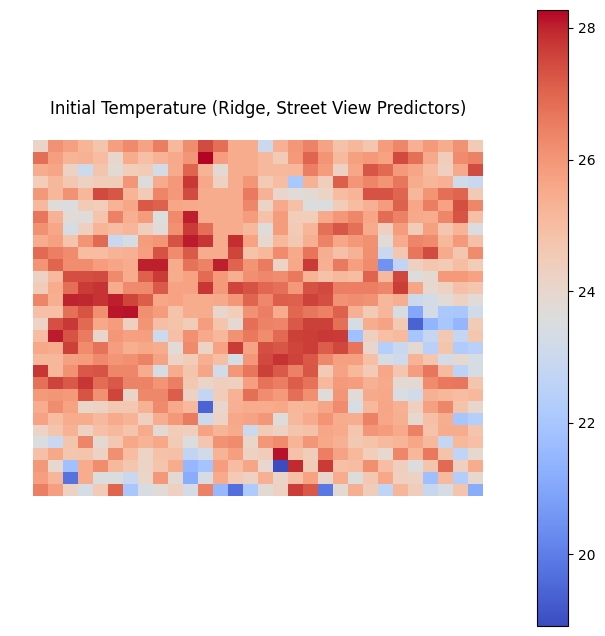

In [6]:
# Predict ridge temperature across all grid cells
for col in predictor_cols:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

X_grid = grid_features[predictor_cols].to_numpy(dtype=float)
grid_features["predicted_temperature_ridge"] = ridge_predict(ridge_model, X_grid)

initial_temperature_map = gpd.GeoDataFrame(grid_features, geometry="geometry", crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
initial_temperature_map.plot(column="predicted_temperature_ridge", cmap="coolwarm", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Initial Temperature (Ridge, Street View Predictors)")
plt.show()

In [7]:
# Compute sensor residuals
sensor_model_df = sensor_cell_df[["sensor_name", "temperature"] + predictor_cols].dropna().copy()
sensor_model_df["ridge_pred_at_sensor"] = ridge_predict(
    ridge_model,
    sensor_model_df[predictor_cols].to_numpy(dtype=float),
)
sensor_model_df["residual"] = sensor_model_df["temperature"] - sensor_model_df["ridge_pred_at_sensor"]

sensors_proj = gdf_sensors.to_crs(initial_temperature_map.crs).copy()
sensors_proj["x"] = sensors_proj.geometry.x
sensors_proj["y"] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[["sensor_name", "x", "y"]], on="sensor_name", how="left"
)
sensor_residuals_df

,sensor_name,temperature,gvi,facades,cars,sky_ratio,road_ratio,ridge_pred_at_sensor,residual,x,y
0,Boston Carter Field,26.214514,0.083996,0.207572,2.875000,0.594129,0.066428,27.064358,-0.849844,234190.269623,898963.472983
1,Boston Gainsborough Parking Garage,28.377312,0.164185,0.056573,7.000000,0.558732,0.267848,25.712348,2.664963,233362.526656,898959.495289
2,Boston Robinson Hall,28.198644,0.164749,0.300726,2.571429,0.466748,0.121130,27.082690,1.115955,234068.072350,898830.485129
3,Boston West Village B,22.676928,0.192916,0.197560,13.400000,0.226279,0.251926,23.342432,-0.665504,233590.883940,898658.685258
4,Boston World Series Way,24.120776,0.187932,0.249794,4.636364,0.420158,0.254900,26.386346,-2.265570,233808.705971,898786.682334


Residual variogram model:
{'model': 'spherical', 'nugget': 0.0, 'sill': 4.32385464797922, 'range': 396.4498930865388, 'score_mse': 3.2407301455832154, 'lag_centers': [155.20359825503238, 258.6726637583873, 362.14172926174217, 465.6107947650971, 672.5489257718069, 776.0179912751619], 'experimental_semivariance': [1.9321824013386812, 3.498729780570097, 5.546006514691946, 4.914672070365042, 0.608352165703266, 6.176935211398887], 'fitted_semivariance': [2.409364322288448, 3.631274133463544, 4.276684339112836, 4.32385464797922, 4.32385464797922, 4.32385464797922]}


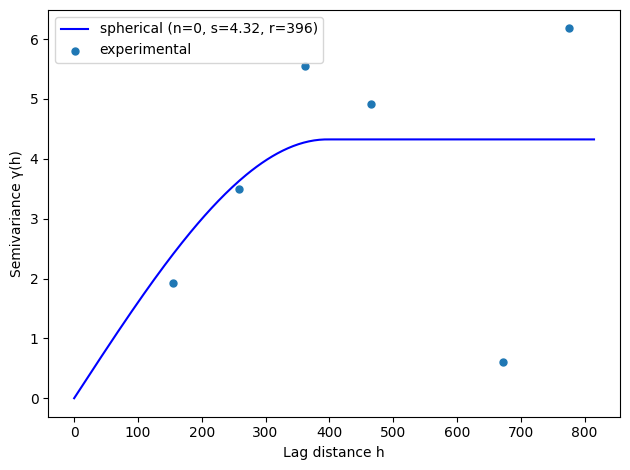

In [8]:
# Fit variogram model on residuals
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

residual_variogram_model = fit_variogram_model(points=res_points, values=res_values)

print("Residual variogram model:")
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

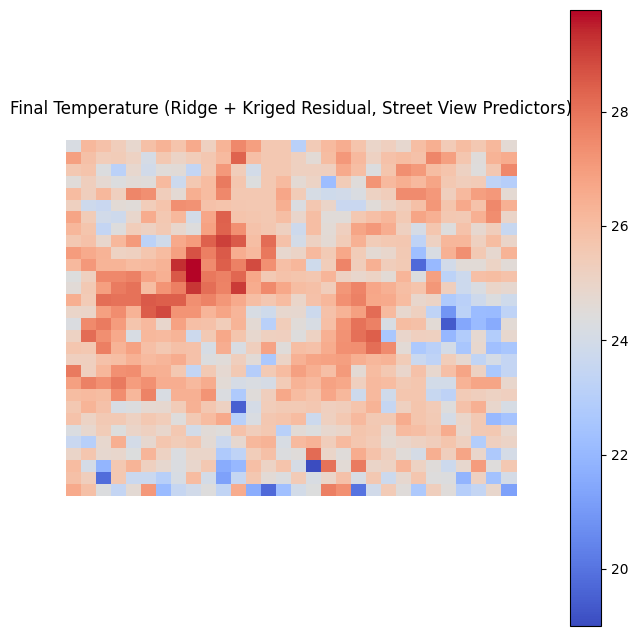

Saved to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_street_view/temperature_sv_kriging_grid.geojson


In [9]:
# Krige residuals and produce final temperature map
LAYERS_DIR = DATA_DIR / "kriging_satellite" / "layers"
LAYERS_DIR.mkdir(parents=True, exist_ok=True)

query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_temperature_map.geometry]
estimated_residuals = ordinary_kriging_predict(
    points=res_points,
    values=res_values,
    fit=residual_variogram_model,
    query_points=query_points,
)

final_temperature_map = initial_temperature_map.copy()
final_temperature_map["estimated_residual"] = estimated_residuals
final_temperature_map["final_temperature"] = (
    final_temperature_map["predicted_temperature_ridge"] + final_temperature_map["estimated_residual"]
)

fig, ax = plt.subplots(figsize=(8, 8))
final_temperature_map.plot(column="final_temperature", cmap="coolwarm", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Final Temperature (Ridge + Kriged Residual, Street View Predictors)")
plt.show()

OUTPUT_PATH = SV_DIR / "temperature_sv_kriging_grid.geojson"
final_temperature_map.to_file(OUTPUT_PATH, driver="GeoJSON")
print(f"Saved to: {OUTPUT_PATH}")